In [1]:
import numpy
from astropy import units as u 
import agama
from scipy.optimize import brentq
import matplotlib.pyplot as plt 

## Goal

- Study a realisitic axis-symmetric potential
    - ZVC
    - Surface of section plots
- Find the relevant orbital families 
    - Get a representative sample over [E,Lz]


In [2]:
def phi_eff_meridional(Rz,pot,Lz):
    Rz=numpy.atleast_2d(Rz)
    R = Rz[:,0]
    z = Rz[:,1]
    pts = numpy.column_stack((R.ravel(), numpy.zeros(R.size), z.ravel()))
    return (pot.eval(pts,pot=True) + 0.5*Lz**2/R.ravel()**2).reshape(R.shape)

def Rcirc(pot,Lz,rmin=1e-3,rmax=2e2):
    """The centripital force and grav force balance"""
    def excess(R):
        point = numpy.array([R,0,0])
        F = pot.eval(point,acc=True)
        F = numpy.abs(numpy.linalg.norm(F))
        centripital = Lz**2 / R**3
        return centripital - F
    return brentq(excess, rmin,rmax)

def R_extrema_zvc(pot,Lz,E,Rmin,Rmax):
    def excess(R):
        point = numpy.array([R,0])
        phi_eff=phi_eff_meridional(point,pot,Lz)[0]
        return E-phi_eff
    return brentq(excess,Rmin,Rmax)


def zvc_meridional_plane(pot, Lz, E, ndirections=100, rmax_ray=1e3):
    r_circ = Rcirc(pot, Lz)
    if E - phi_eff_meridional([r_circ, 0], pot, Lz)[0] < 0:
        raise ValueError("E is below the circular-orbit energy")
    Rmin = R_extrema_zvc(pot, Lz, E, 1e-3, r_circ)
    Rmax = R_extrema_zvc(pot, Lz, E, r_circ, rmax_ray)
    max_extent = max(Rmax - r_circ, r_circ - Rmin)  # farthest ray length needed, kept small enough to stay in R>0

    def excess(raylen, direction):
        R = r_circ + raylen*direction[0]
        z = raylen*direction[1]
        return E - phi_eff_meridional([R, z], pot, Lz)[0]

    angles = numpy.linspace(0, 2*numpy.pi, ndirections, endpoint=False)
    directions = numpy.column_stack((numpy.cos(angles), numpy.sin(angles)))
    raylengths = numpy.full(ndirections, numpy.nan)
    for i, d in enumerate(directions):
        # shrink so the ray end stays at R > 0
        b = 3*max_extent
        if d[0] < 0:
            b = min(b, 0.999*r_circ/abs(d[0]))
        if excess(b, d) < 0:
            raylengths[i] = brentq(excess, 0, b, args=(d,))
    Rz = raylengths[:, None]*directions
    Rz[:, 0] += r_circ
    return Rz

def zvc_R_PR(pot, Lz, E, tol = 1e-5):
    # find the PR max for each value of R along the curve that's allowed...
    Rmin = R_extrema_zvc(pot,Lz,E,1e-3,rcirc)
    Rmax = R_extrema_zvc(pot,Lz,E,rcirc,1e3)
    Rs = numpy.linspace((1+tol)*Rmin,(1-tol)*Rmax,100)
    Rz = numpy.column_stack((Rs,0*Rs))
    PR=numpy.sqrt(2*(E_test - phi_eff_meridional(Rz,pot,Lz)))
    # stack them 
    Rs = numpy.hstack((Rs,Rs[-1::-1]))
    PR = numpy.hstack((PR,-PR[-1::-1]))
    return Rs, PR


def PR_max(R,pot,Lz,E):
    Rz = numpy.array([R,0])
    return numpy.sqrt(2*(E - phi_eff_meridional(Rz,pot,Lz)))


def Pz_max(R,PR,pot,Lz,E):
    Rz = numpy.array([R,0])
    return numpy.sqrt(2 * ( E - (phi_eff_meridional(Rz,pot,Lz)[0] + PR**2 / 2)))

def meridional_random_sampler(pot, Lz, E):
    rcirc = Rcirc(pot, Lz)
    Rmin = R_extrema_zvc(pot, Lz, E, 1e-3, rcirc)
    Rmax = R_extrema_zvc(pot, Lz, E, rcirc, 1e3)

    R0 = Rmin + (Rmax - Rmin)*numpy.random.rand()
    PRmax = PR_max(R0, pot, Lz, E)[0]          # was E_test
    PR = PRmax*(2*numpy.random.rand() - 1)     # allow both signs
    Pz = Pz_max(R0, PR, pot, Lz, E)            # no random factor
    return numpy.array([R0, 0, 0, PR, Lz/R0, Pz])

def SOS_z_cross(orb):
    timecross=orb.z.roots()
    timecross = timecross[orb.z(timecross, der=1) >= 0]
    traj = orb(orb)
    trajcross = orb(timecross)
    return timecross, traj, trajcross

def cartesian_to_cylindrical(w):
    """[x,y,z,vx,vy,vz] -> [R,theta,z,PR,Ptheta,Pz] (unit mass, canonical momenta)."""
    w = numpy.asarray(w, dtype=float)
    x, y, z, vx, vy, vz = w.T
    R = numpy.hypot(x, y)
    theta = numpy.arctan2(y, x)
    PR = (x*vx + y*vy) / R
    Ptheta = x*vy - y*vx          # = R^2 * thetadot = Lz
    Pz = vz
    return numpy.column_stack((R, theta, z, PR, Ptheta, Pz)).reshape(w.shape)

def cylindrical_to_cartesian(q):
    """[R,theta,z,PR,Ptheta,Pz] -> [x,y,z,vx,vy,vz] (unit mass)."""
    q = numpy.asarray(q, dtype=float)
    R, theta, z, PR, Ptheta, Pz = q.T
    c, s = numpy.cos(theta), numpy.sin(theta)
    x, y = R*c, R*s
    vtheta = Ptheta / R           # tangential speed R*thetadot
    vx = PR*c - vtheta*s
    vy = PR*s + vtheta*c
    vz = Pz
    return numpy.column_stack((x, y, z, vx, vy, vz)).reshape(q.shape)

In [3]:
unitL = u.kpc
unitV = u.km/u.s
unitM = u.Msun
agama.setUnits(mass=1, length=1, velocity=1)
G=agama.G
# set up the units

In [4]:
# set up the problem 
# initialize our potential 
potential   =   "McMillan17.ini"
path        =   agama.__path__[0] + "/data/" + "McMillan17.ini"
pot         =   agama.Potential(path)
massCluster =   1e5
scaleRadius =   5e-3
pot_cluster =   agama.Potential(type="plummer", mass=massCluster, scaleRadius=scaleRadius)

In [20]:
# the max energy given an Lz? well. E circ is the lowest energy. 
# pick an Lz
Lz = 5*220
rcirc = Rcirc(pot,Lz)

In [21]:
# pick a moderate energy for the SOS plot 
E_min = phi_eff_meridional([rcirc, 0], pot, Lz)[0]
E_max = 0.0   # or Φ(∞); use the cap from case 2
Es = numpy.linspace(E_min, E_max, 12)[1:-5]
# E_test=(5/4)*Es.mean()
E_test=Es[0]
Rz=zvc_meridional_plane(pot,Lz,E_test)
Rz=numpy.vstack((Rz,Rz[0]))


100 orbits complete (40.44 orbits/s)


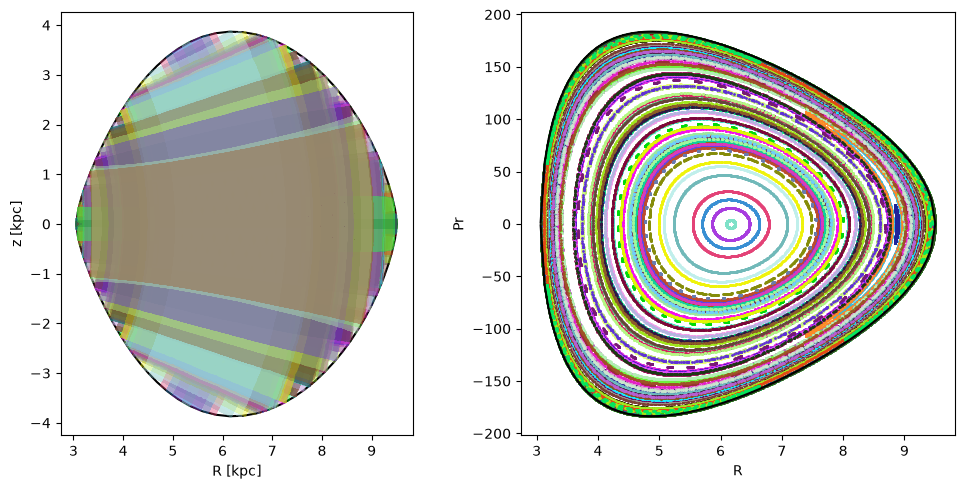

In [22]:
Rs, PR = zvc_R_PR(pot, Lz, E_test, tol = 1e-5)

nsamples = 100
ics = numpy.zeros((nsamples,6))
for i in range(nsamples):
    ics[i]= meridional_random_sampler(pot,Lz,E_test)

orb=agama.orbit(ic=ics,potential=pot,time=100,dtype=object)
tcross=[];trajs=[];trajscross=[]
qcrossings=[]
for orbit in orb:
    timecross, traj, trajcross = SOS_z_cross(orbit)
    qtraj = cartesian_to_cylindrical(traj)
    qcross = cartesian_to_cylindrical(trajcross)
    trajscross.append(trajcross)
    qcrossings.append(qcross)
    trajs.append(qtraj)
fig,axis=plt.subplots(1,2,figsize=(10,5))

axis[1].plot(Rs,PR,color="k",)
axis[0].plot(Rz[:,0],Rz[:,1],color="k")
for i in range(nsamples):
    c = numpy.random.rand(3)
    axis[0].plot(trajs[i][:,0],trajs[i][:,2],color=c,alpha=0.4)
    axis[1].scatter(qcrossings[i][:,0],qcrossings[i][:,3],s=1,color=c)

axis[1].set(xlabel="R", ylabel="Pr")
axis[0].set(aspect="equal",xlabel="R [kpc]", ylabel="z [kpc]")
fig.tight_layout()
fig.savefig("meridional_sos_test.png")


9.4611998381273

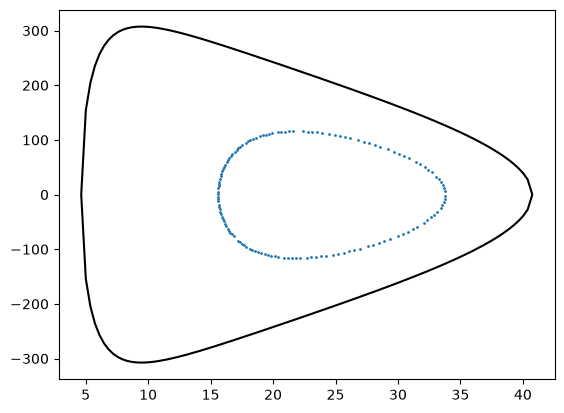

In [85]:

Rs, PR = zvc_R_PR(pot, Lz, E_test, tol = 1e-5)
fig,axis=plt.subplots(1,1)
axis.plot(Rs,PR,color="k")

axis.scatter(qcross[:,0],qcross[:,3],s=1)